In [5]:
import numpy as np
import matplotlib.pyplot as plt

def bisection_method(f, a, b, tol, N0):
    FA = f(a)
    FB = f(b)
    if FA * FB > 0:
        raise ValueError("f(a) y f(b) deben tener signos opuestos")
    
    i = 1
    while i <= N0:
        p = a + (b - a) / 2
        FP = f(p)
        if FP == 0 or (b - a) / 2 < tol:
            return p, i
        i += 1
        if FA * FP > 0:
            a = p
            FA = FP
        else:
            b = p
    raise Exception("Se agotó el número máximo de iteraciones")

In [6]:
f1 = lambda x: x**3 - x - 1
p_approx, iters = bisection_method(f1, 1, 2, 1e-4, 100)
print(p_approx, iters)

f2 = lambda x: x**3 - 7*x**2 + 14*x - 6
intervals = [(0, 1), (1, 3.2), (3.2, 4)]
for iv_a, iv_b in intervals:
    root, it = bisection_method(f2, iv_a, iv_b, 1e-2, 100)
    print(root, it)

f3 = lambda x: x - 2 * np.sin(x)
root3, _ = bisection_method(f3, 1.8, 2.0, 1e-5, 100)
print(root3)

f4 = lambda x: x - np.tan(x)
root4, _ = bisection_method(f4, 4.4, 4.6, 1e-5, 100)
print(root4)

f5 = lambda x: x**2 - 1 - np.exp(1 - x**2)
root5, _ = bisection_method(f5, -2, 0, 1e-3, 100)
print(root5)

1.32476806640625 14
0.5859375 7
3.0023437500000005 8
3.41875 7
1.8954895019531248
4.493414306640625
-1.2509765625


In [7]:
L = 10.0
r = 1.0
V_target = 12.4
f_trough = lambda h: L * (0.5 * np.pi * r**2 - r**2 * np.arcsin(h/r) - h * np.sqrt(r**2 - h**2)) - V_target
h_val, _ = bisection_method(f_trough, 0.0, 1.0, 0.01, 100)
depth = r - h_val
print(h_val, depth)

s0 = 300.0
m = 0.25
k = 0.1
g = 9.81
f_fall = lambda t: s0 - (m*g/k)*t + ((m**2 * g)/(k**2)) * (1 - np.exp(-k*t/m))
t_val, _ = bisection_method(f_fall, 0.0, 30.0, 0.01, 1000)
print(t_val)

0.1640625 0.8359375
14.72900390625


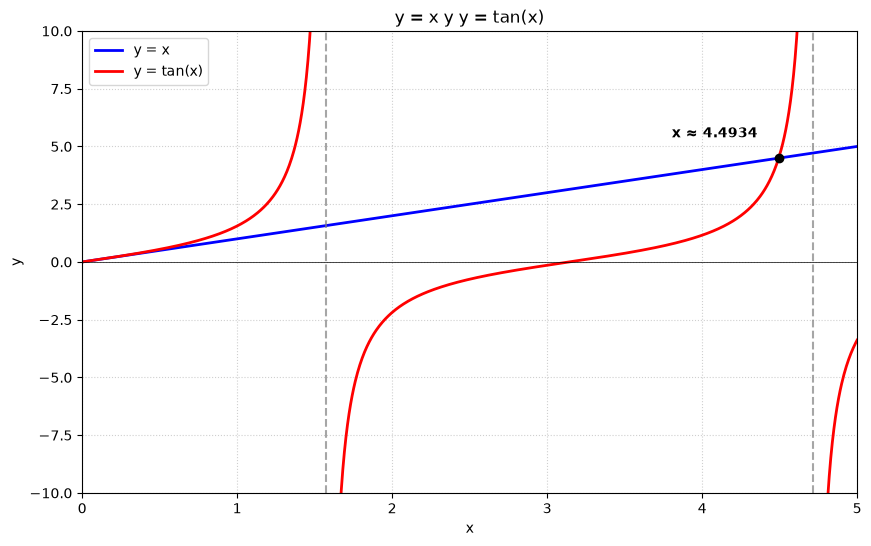

In [10]:
x_vals = np.linspace(0, 5, 1000)
y_line = x_vals
y_tan = np.tan(x_vals)
y_tan[np.abs(y_tan) > 20] = np.nan

plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_line, label='y = x', color='blue', linewidth=2)
plt.plot(x_vals, y_tan, label='y = tan(x)', color='red', linewidth=2)
plt.axvline(x=np.pi/2, color='gray', linestyle='--', alpha=0.7)
plt.axvline(x=3*np.pi/2, color='gray', linestyle='--', alpha=0.7)

plt.scatter([root4], [root4], color='black', zorder=5)
plt.annotate(f'x \u2248 {root4:.4f}', (root4, root4), textcoords="offset points", xytext=(-15,15), ha='right', fontweight='bold')

plt.ylim(-10, 10)
plt.xlim(0, 5)
plt.xlabel('x')
plt.ylabel('y')
plt.title('y = x y y = tan(x)')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.savefig('grafica_biseccion_tan.png', dpi=300, bbox_inches='tight')
plt.show()